# UPI Fraud Detection - Logistic Regression Baseline

This notebook trains the first baseline classifier after preprocessing.

Workflow:
1. Load the raw dataset
2. Drop identifier columns
3. Separate target and features
4. Handle missing values
5. One-hot encode categorical features
6. Split the dataset into training and testing sets
7. Train Logistic Regression
8. Evaluate the model

## 1. Imports and Dataset Load

We keep the preprocessing inside this notebook so the baseline is fully reproducible on its own.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('..') / 'dataset' / 'upi_fraud_dataset_behavioral_v2.csv'
df = pd.read_csv(DATA_PATH)

df.head()

,transaction_id,transaction_date,transaction_time,customer_id,sender_upi,receiver_upi,amount,transaction_type,merchant_category,sender_account_age_days,receiver_account_age_days,device_id,device_changed,known_device,trusted_device,os_type,app_name,ip_address,location,location_changed,new_beneficiary,beneficiary_frequency,transactions_last_10_minutes,transactions_last_hour,transactions_last_24_hours,amount_sent_last_24_hours,amount_received_last_24_hours,unique_receivers_today,balance_before,balance_after,decimal_pattern,money_flow_pattern,customer_behaviour_deviation,is_fraud,fraud_type
0,TXN0096196,2026-04-07,00:07:47,CUST02924,ishaantank6535@okhdfcbank,vsingh6378@paytm,745.21,P2P,NaN,124,235,DEV-48EA6BD0FFEE,False,True,True,Android,Paytm,58.35.75.178,Pune,False,True,0,0,0,0,0.0,0.0,0,44705.71,43960.50,False,Refund,0.2219,0,NaN
1,TXN0067907,2026-04-07,00:08:45,CUST04012,harinakshikar7902@oksbi,bahadurjitchandran9738@okhdfcbank,1230.44,P2M,Electronics,308,146,DEV-B7CD99AC4D9B,False,True,True,Android,Paytm,171.220.144.175,Mumbai,False,True,0,0,0,0,0.0,0.0,0,1269254.65,1268024.21,False,Travel Payment,0.1813,0,NaN
2,TXN0008569,2026-04-07,00:10:50,CUST02392,sathvikswamy9935@paytm,lavanyasen2814@okaxis,643.95,P2P,NaN,113,322,DEV-CDC3A225D3F6,False,True,True,Android,Paytm,130.196.162.207,Lucknow,False,True,0,0,0,0,0.0,0.0,0,343755.85,343111.90,False,Gift,0.4219,0,NaN
3,TXN0083623,2026-04-07,00:13:39,CUST01883,aayushwali4880@paytm,finnchanda3055@okicici,203.08,P2P,NaN,627,1098,DEV-3766EBCA617C,False,True,True,iOS,AmazonPay,79.123.13.235,Nagpur,False,True,0,0,0,0,0.0,0.0,0,261606.72,261403.64,False,Personal Transfer,0.2455,0,NaN
4,TXN0060281,2026-04-07,00:20:18,CUST04883,amritalalla5990@okicici,merchant8860@apl,401.43,P2M,Rent,1000,266,DEV-B50D1ADAFF11,False,True,True,Android,BHIM,92.106.65.184,Jaipur,False,True,0,0,0,0,0.0,0.0,0,120217.53,119816.10,False,Bills Payment,0.1768,0,NaN


## 2. Preprocessing

We drop identifier columns, separate the target, fill missing values, and encode categorical fields using one-hot encoding.

In [8]:
target_column = 'is_fraud'
identifier_columns = [
    'transaction_id',
    'customer_id',
    'sender_upi',
    'receiver_upi',
    'device_id',
    'ip_address',
    'fraud_type',
]

available_identifier_columns = [column for column in identifier_columns if column in df.columns]
data = df.drop(columns=available_identifier_columns).copy()

y = data[target_column].copy()
X = data.drop(columns=[target_column]).copy()

transaction_date = pd.to_datetime(X['transaction_date'], errors='coerce')
X['transaction_dayofweek'] = transaction_date.dt.dayofweek
X['transaction_day'] = transaction_date.dt.day
X['transaction_month'] = transaction_date.dt.month
X['transaction_year'] = transaction_date.dt.year
X['transaction_hour'] = pd.to_datetime(X['transaction_time'], format='%H:%M:%S', errors='coerce').dt.hour
X = X.drop(columns=['transaction_date', 'transaction_time'])

categorical_columns = X.select_dtypes(include=['object', 'bool']).columns.tolist()
numeric_columns = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

for column in categorical_columns:
    if column == 'merchant_category':
        X[column] = X[column].fillna('P2P')
    else:
        X[column] = X[column].fillna('NONE')

for column in numeric_columns:
    X[column] = X[column].fillna(X[column].median())

X_encoded = pd.get_dummies(X, columns=categorical_columns, drop_first=False)

print(f'Encoded feature shape: {X_encoded.shape}')
print(f'Target distribution: {y.value_counts().to_dict()}')

Encoded feature shape: (100000, 76)
Target distribution: {0: 95000, 1: 5000}


## 3. Train/Test Split

We use an 80/20 split and stratify by the target so both sets keep the same fraud ratio.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train fraud rate: {y_train.mean():.4%}')
print(f'y_test fraud rate: {y_test.mean():.4%}')

X_train shape: (80000, 76)
X_test shape: (20000, 76)
y_train fraud rate: 5.0000%
y_test fraud rate: 5.0000%


## 4. Train Logistic Regression

This is the baseline model. It is fast, interpretable, and gives us a reference point before we move to more complex models.

In [11]:
log_reg = LogisticRegression(max_iter=5000, solver='liblinear', class_weight='balanced', random_state=42)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

## 5. Evaluate the Model

For fraud detection, recall and precision matter at least as much as accuracy. We also inspect the confusion matrix and ROC-AUC.

           Logistic Regression
Accuracy              0.887600
Precision             0.263098
Recall                0.693000
F1 Score              0.381398
ROC-AUC               0.861249

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94     19000
           1       0.26      0.69      0.38      1000

    accuracy                           0.89     20000
   macro avg       0.62      0.80      0.66     20000
weighted avg       0.95      0.89      0.91     20000



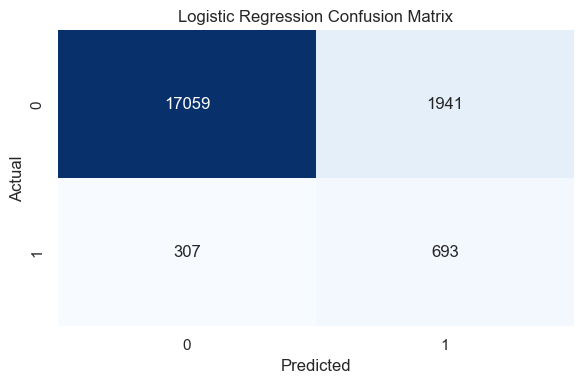

In [12]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1 Score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
}

metrics_df = pd.DataFrame(metrics, index=['Logistic Regression']).T
print(metrics_df)

print('\nClassification Report:')
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 6. Next Step

The next notebook can train Decision Tree, Random Forest, and XGBoost using the same preprocessing flow so the models are comparable.